# 4) RC Series Circuit Simulation

This notebook simulates the impedance of a series RC circuit:
$$
Z_{RC} = R + 1 / (j ω C)
$$

Goals:
- Generate a frequency vector
- Compute real/imag/magnitude/phase
- Add Gaussian noise to both components
- Visualise Nyquist and Bode behaviour
- Export dataset to `data/simulated/`


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from src.simulation.rc_circuit import simulate_rc_series

In [2]:
# Simulation Parameters
R = 100      # ohms
C = 1e-6     # 1 µF
f_min = 1
f_max = 1e5
num_points = 400

frequencies = np.logspace(np.log10(f_min), np.log10(f_max), num_points)
noise_level = 0.1  # noise on both real and imaginary parts

Z = simulate_rc_series(R, C, frequencies, noise_level=noise_level)

real_Z = Z.real
imag_Z = Z.imag
mag_Z = np.abs(Z)
phase_Z = np.angle(Z)


# Visualisations

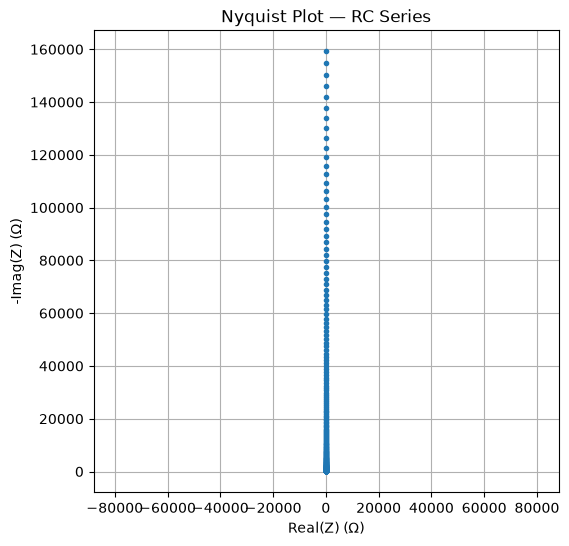

In [3]:
# Nyquist Plot
plt.figure(figsize=(6,6))
plt.plot(real_Z, -imag_Z, 'o', markersize=3)
plt.title("Nyquist Plot — RC Series")
plt.xlabel("Real(Z) (Ω)")
plt.ylabel("-Imag(Z) (Ω)")
plt.grid(True)
plt.axis('equal')
plt.show()


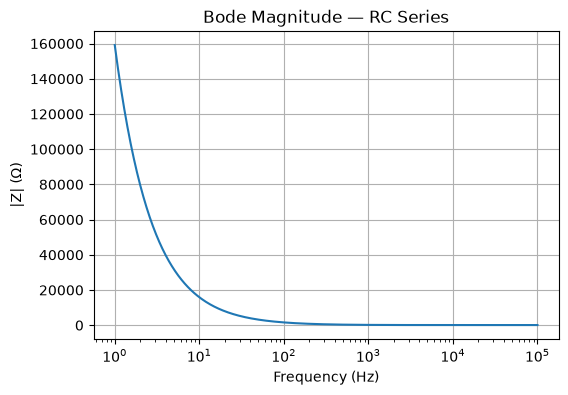

In [4]:
# Bode Magnitude
plt.figure(figsize=(6,4))
plt.semilogx(frequencies, mag_Z)
plt.title("Bode Magnitude — RC Series")
plt.xlabel("Frequency (Hz)")
plt.ylabel("|Z| (Ω)")
plt.grid(True)
plt.show()


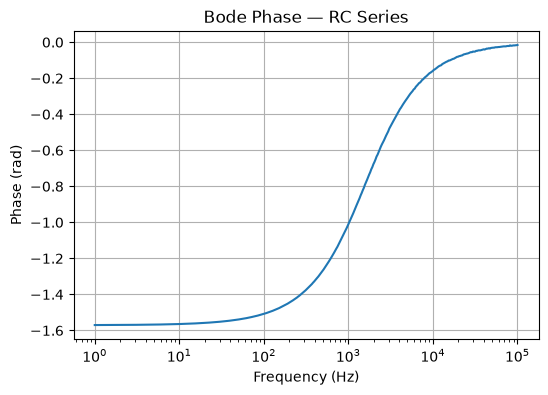

In [5]:
# Bode Phase
plt.figure(figsize=(6,4))
plt.semilogx(frequencies, phase_Z)
plt.title("Bode Phase — RC Series")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Phase (rad)")
plt.grid(True)
plt.show()


# Export Dataset

In [6]:
df = pd.DataFrame({
    "frequency": frequencies,
    "real": real_Z,
    "imag": imag_Z,
    "magnitude": mag_Z,
    "phase_rad": phase_Z
})

output_path = "../data/simulated/rc_R100_C1uF.csv"
df.to_csv(output_path, index=False)

output_path


'../data/simulated/rc_R100_C1uF.csv'

# Summary

This notebook generated a simulated impedance dataset for a series RC circuit.
The dataset was saved in `data/simulated/rc_R100_C1uF.csv`.